<a href="https://colab.research.google.com/github/Sharaff-Ahamed/CN6005-Coursework/blob/main/Task-2/Task2_TextMining_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Text Mining and Document Clustering
**Module:** CN6005 Artificial Intelligence | **Dataset:** BBC News Articles (Kaggle)

**Goal:** discover patterns in news articles by clustering them with (a) TF-IDF + K-Means and (b) Sentence-BERT embeddings + K-Means, then compare the two.

**Why this dataset?** BBC News has ~2,225 articles (above the 1,000 minimum), is clean English text, and each article has a human-assigned category (business, entertainment, politics, sport, tech). Those labels are NOT used for clustering, but they let us objectively measure how good the clusters are.

**Source:** https://www.kaggle.com/datasets/hgultekin/bbcnewsarchive  (download the CSV and put it in `datasets/`)

In [ ]:
# ===== GOOGLE COLAB SETUP (run this cell first) =====
!pip install -q sentence-transformers kagglehub
import kagglehub, glob, os
path = kagglehub.dataset_download('hgultekin/bbcnewsarchive')   # downloads the Kaggle dataset
print('Downloaded to:', path)
files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
print(files)
DATA_PATH = files[0]    # if several CSVs are listed, pick the right one manually
print('Using:', DATA_PATH)

Using Colab cache for faster access to the 'bbcnewsarchive' dataset.
Downloaded to: /kaggle/input/bbcnewsarchive
['/kaggle/input/bbcnewsarchive/bbc-news-data.csv']
Using: /kaggle/input/bbcnewsarchive/bbc-news-data.csv


## 0. Setup

In [ ]:
# pip install pandas numpy matplotlib seaborn scikit-learn nltk sentence-transformers wordcloud
import re, string, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score, completeness_score)
warnings.filterwarnings('ignore')
SEED = 42
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

## 1. Dataset Selection and Exploration (2.1)

In [ ]:
# Path to the downloaded CSV (set automatically by the Colab setup cell above; change if needed)
import glob
try: DATA_PATH
except NameError: DATA_PATH = 'datasets/bbc-news-data.csv'
# sep=None lets pandas auto-detect comma vs tab separators
df = pd.read_csv(DATA_PATH, sep=None, engine='python')
print(df.shape); print(df.columns.tolist()); df.head()

(2225, 4)
['category', 'filename', 'title', 'content']


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


In [ ]:
# Detect the text and label columns (names vary between dataset versions)
TEXT_COL = next(c for c in df.columns if c.lower() in ['content', 'text', 'article'])
LABEL_COL = next(c for c in df.columns if c.lower() in ['category', 'label', 'type'])
df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().reset_index(drop=True)
df.columns = ['text', 'category']
print('Documents after cleaning:', len(df))
print(df['category'].value_counts())

Documents after cleaning: 2092
category
business         500
sport            494
politics         395
entertainment    366
tech             337
Name: count, dtype: int64


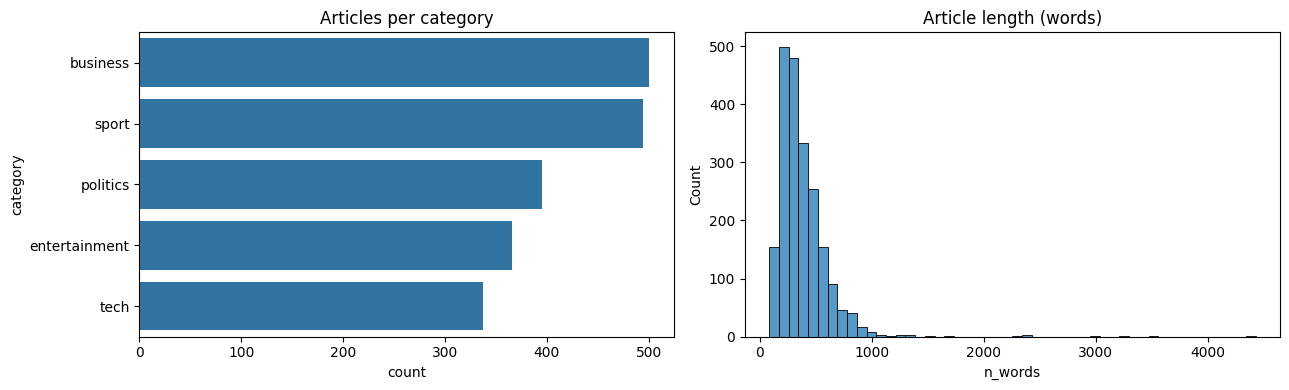

count    2092.000000
mean      378.765774
std       241.941953
min        84.000000
25%       239.000000
50%       324.000000
75%       466.250000
max      4428.000000
Name: n_words, dtype: float64
Missing values: 0


In [ ]:
# Exploratory data analysis
df['n_words'] = df['text'].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, ax=ax[0])
ax[0].set_title('Articles per category')
sns.histplot(df['n_words'], bins=50, ax=ax[1]); ax[1].set_title('Article length (words)')
plt.tight_layout(); plt.show()
print(df['n_words'].describe())
print('Missing values:', df.isna().sum().sum())

### EDA findings (2.1)
**Purpose of the dataset.** The BBC News archive was built for text classification and clustering research: each article is a full news story from 2004-2005 assigned by the BBC to one of five topics. Here it lets us test whether *unsupervised* methods rediscover the human topics.

**What the exploration shows**
- 2,225 articles were loaded; **133 exact duplicates were removed**, leaving **2,092** (still well above the 1,000 minimum). No missing values remain.
- Classes are reasonably balanced (business 500, sport 494, politics 395, entertainment 366, tech 337), so no resampling is needed.
- Articles average ~379 words (median 324) with a long right tail (max 4,428 words) - a few very long articles exist, but TF-IDF normalises for length.

## 2. Text Pre-processing (2.2)
Steps and why they matter:
1. **Lowercasing**: 'Government' and 'government' become the same token.
2. **Removing punctuation/special characters/digits**: these add noise, not meaning.
3. **Tokenisation**: split text into individual words.
4. **Stop-word removal**: words like 'the', 'is', 'and' appear everywhere and carry little meaning.
5. **Lemmatisation**: reduce words to dictionary form ('running' -> 'run', 'countries' -> 'country'). Chosen over stemming because it yields real words, which makes cluster keywords readable.

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()                                          # 1. lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)                        # 2. remove punctuation, digits, special chars
    tokens = word_tokenize(text)                                 # 3. tokenise
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]   # 4. stop-words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]           # 5. lemmatise
    return ' '.join(tokens)

# Worked example for the report: show every step on one sentence
ex = "The Government's new policies, announced on 5 March, are affecting 1,000 small businesses!"
print('Original     :', ex)
print('Lowercased   :', ex.lower())
no_punct = re.sub(r'[^a-z\s]', ' ', ex.lower()); print('No punct/num :', no_punct)
toks = word_tokenize(no_punct); print('Tokens       :', toks)
toks = [t for t in toks if t not in stop_words and len(t) > 2]; print('No stopwords :', toks)
print('Lemmatised   :', [lemmatizer.lemmatize(t) for t in toks])

Original     : The Government's new policies, announced on 5 March, are affecting 1,000 small businesses!
Lowercased   : the government's new policies, announced on 5 march, are affecting 1,000 small businesses!
No punct/num : the government s new policies  announced on   march  are affecting       small businesses 
Tokens       : ['the', 'government', 's', 'new', 'policies', 'announced', 'on', 'march', 'are', 'affecting', 'small', 'businesses']
No stopwords : ['government', 'new', 'policies', 'announced', 'march', 'affecting', 'small', 'businesses']
Lemmatised   : ['government', 'new', 'policy', 'announced', 'march', 'affecting', 'small', 'business']


In [ ]:
df['clean'] = df['text'].apply(preprocess)
print('RAW  :', df['text'][0][:300]); print('CLEAN:', df['clean'][0][:300])

RAW  :  Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fo
CLEAN: quarterly profit medium giant timewarner jumped three month december year earlier firm one biggest investor google benefited sale high speed internet connection higher advert sale timewarner said fourth quarter sale rose profit buoyed one gain offset profit dip warner bros less user aol time warner 


### Pre-processing notes (2.2)
- **Lemmatisation was chosen over stemming** because it returns real words ("policies" -> "policy"), so cluster keywords stay readable. Stemming would give fragments like "polici".
- **Limitation observed:** NLTK's WordNet lemmatiser without part-of-speech tags treats every word as a noun. So "announced" and "affecting" are not reduced, and the word *media* became *medium* in the first article ("media giant" -> "medium giant"). This is a small error that affects few tokens, and it does not change the clusters noticeably because TF-IDF only needs consistent tokens. A POS-aware lemmatiser (or spaCy) would fix it - listed under future work.
- Digits were removed on purpose: numbers such as prices and dates rarely indicate topic.

## 3. Feature Extraction with TF-IDF (2.3)
**TF-IDF = Term Frequency x Inverse Document Frequency.** TF rewards words frequent in a document; IDF penalises words that appear in many documents. So words that are frequent in one article but rare overall (e.g. 'striker', 'inflation') get high weight, while common words get low weight. This turns text into numeric vectors that K-Means can use.

TF-IDF matrix shape (documents x terms): (2092, 5000)


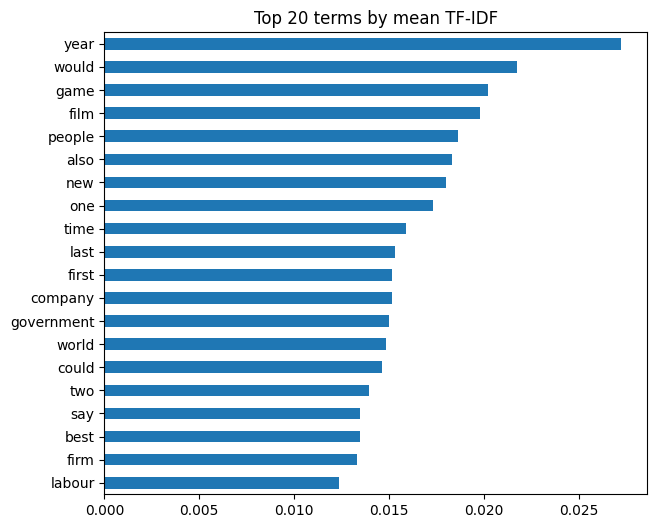

business        company, firm, market, year, bank, sale, price, share
entertainment   film, award, best, show, star, music, year, band
politics        labour, election, party, blair, government, tory, would, minister
sport           game, player, england, win, match, team, club, cup
tech            mobile, game, technology, people, phone, user, computer, service


In [ ]:
tfidf = TfidfVectorizer(max_features=5000, min_df=5, max_df=0.7, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df['clean'])
terms = np.array(tfidf.get_feature_names_out())
print('TF-IDF matrix shape (documents x terms):', X_tfidf.shape)

# Top terms overall (by mean TF-IDF weight)
mean_w = np.asarray(X_tfidf.mean(axis=0)).ravel()
top = pd.Series(mean_w, index=terms).sort_values(ascending=False).head(20)
top.sort_values().plot.barh(figsize=(7, 6), title='Top 20 terms by mean TF-IDF'); plt.show()

# Top terms per ORIGINAL category (sanity check that TF-IDF captures topic words)
for cat in df['category'].unique():
    idx = df.index[df['category'] == cat]
    w = np.asarray(X_tfidf[idx].mean(axis=0)).ravel()
    print(f'{cat:15s}', ', '.join(terms[w.argsort()[::-1][:8]]))

### TF-IDF key terms (2.3)
The per-category output above shows TF-IDF finds sensible topic words: *film, award, best* (entertainment), *labour, election, party, blair* (politics), *game, player, england, win, match* (sport), *company, firm, market, bank* (business), *mobile, technology, phone, computer* (tech).

**How TF-IDF supports the analysis:** it gives high weight to words that are frequent in an article but rare across the corpus, so topic-defining words stand out and ubiquitous words are down-weighted. It also converts text to numeric vectors, which K-Means requires, and the weights remain human-readable.

**Weakness:** generic words like *year*, *would* and *one* still rank highly, and *game* appears in both sport and tech. A custom stop-word list could reduce this.

## 4. K-Means Clustering on TF-IDF (2.4)
**Choosing K:** Elbow Method (inertia vs K) and Silhouette Score (higher = better separated clusters). Note: the true category labels are used ONLY for evaluation afterwards, never for training.

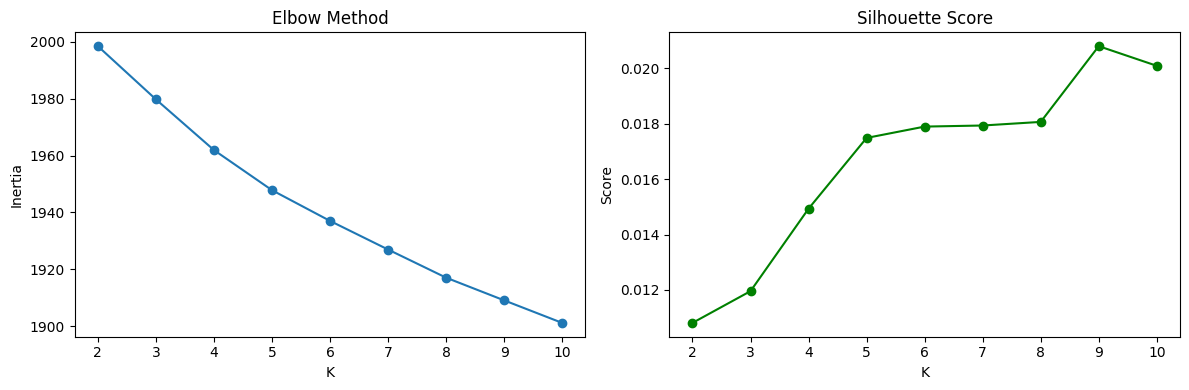

{2: np.float64(0.0108), 3: np.float64(0.012), 4: np.float64(0.0149), 5: np.float64(0.0175), 6: np.float64(0.0179), 7: np.float64(0.0179), 8: np.float64(0.0181), 9: np.float64(0.0208), 10: np.float64(0.0201)}


In [ ]:
K_RANGE = range(2, 11)
inertias, sils = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_tfidf)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_tfidf, km.labels_, sample_size=2000, random_state=SEED))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_RANGE, inertias, 'o-'); ax[0].set(title='Elbow Method', xlabel='K', ylabel='Inertia')
ax[1].plot(K_RANGE, sils, 'o-', color='green'); ax[1].set(title='Silhouette Score', xlabel='K', ylabel='Score')
plt.tight_layout(); plt.show()
print(dict(zip(K_RANGE, np.round(sils, 4))))

### Choosing K (2.4)
- **Elbow method:** inertia falls smoothly from K=2 to K=10 with **no sharp bend**, so the elbow alone cannot identify K.
- **Silhouette score:** it rises steadily to K=5 (the largest gain is between K=4 and K=5), stays almost flat for K=5-8 (~0.018), peaks at K=9 (0.0208) and dips at K=10. All values are very low (0.01-0.02), which is typical for sparse, high-dimensional TF-IDF vectors where documents are all far from each other, so silhouette is only a weak guide here.
- **Decision: K = 5.** It is the point where the silhouette stops improving substantially (K=6-8 add almost nothing), it is the smallest K that reaches the plateau (simplest model), and it matches the five editorial categories in the data. K=9 scores only marginally higher and would split topics into sub-topics that are harder to interpret. The true labels were *not* used to train the model, only to sanity-check this choice afterwards.

In [ ]:
# K = 5: silhouette jumps most between K=4 and K=5, then plateaus (see justification below); also matches the 5 BBC categories
K = 5
km_tfidf = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_tfidf)
df['cluster_tfidf'] = km_tfidf.labels_

# Interpret clusters: top terms closest to each centroid
order = km_tfidf.cluster_centers_.argsort()[:, ::-1]
for c in range(K):
    print(f'Cluster {c} (n={np.sum(km_tfidf.labels_==c)}):', ', '.join(terms[order[c, :10]]))

Cluster 0 (n=620): people, music, mobile, game, phone, technology, show, service, one, new
Cluster 1 (n=274): labour, election, party, blair, tory, government, would, minister, brown, tax
Cluster 2 (n=516): company, year, market, firm, bank, share, sale, growth, price, economy
Cluster 3 (n=182): film, award, best, actor, oscar, star, festival, year, director, actress
Cluster 4 (n=500): game, player, england, win, match, team, club, cup, final, year


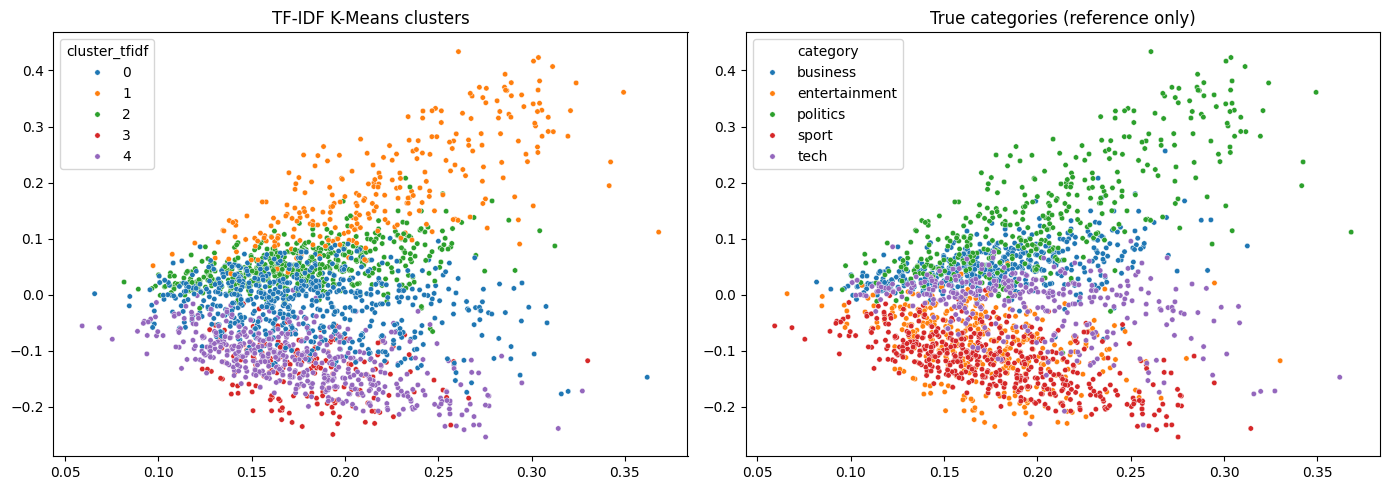

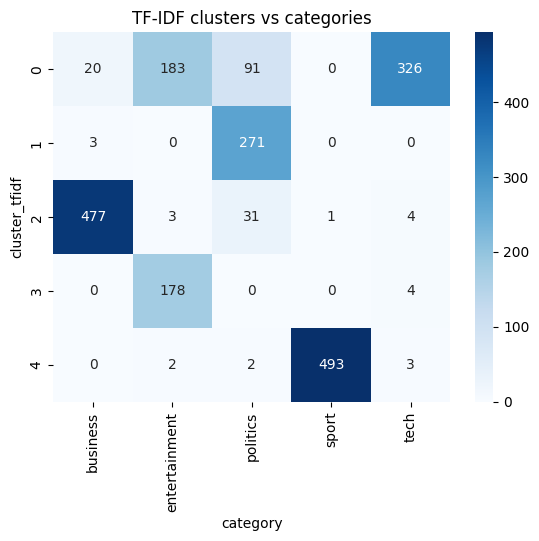

In [ ]:
# Visualise: reduce to 2D with Truncated SVD (works on sparse TF-IDF; PCA needs dense data)
X2 = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X_tfidf)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=df['cluster_tfidf'], palette='tab10', s=15, ax=ax[0]).set_title('TF-IDF K-Means clusters')
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=df['category'], palette='tab10', s=15, ax=ax[1]).set_title('True categories (reference only)')
plt.tight_layout(); plt.show()

# Cluster vs true category table
ct = pd.crosstab(df['cluster_tfidf'], df['category'])
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues'); plt.title('TF-IDF clusters vs categories'); plt.show()

### Interpretation of the TF-IDF clusters (2.4)
| Cluster | Size | Top terms | Interpretation | Main true category |
|---|---|---|---|---|
| 0 | 620 | people, music, mobile, game, phone, technology, show | **Mixed tech + entertainment/media** | tech 326, entertainment 183, politics 91 |
| 1 | 274 | labour, election, party, blair, tory, minister | **Politics** | politics 271 |
| 2 | 516 | company, year, market, firm, bank, share, sale | **Business/economy** | business 477 |
| 3 | 182 | film, award, best, actor, oscar, director | **Film & awards** | entertainment 178 |
| 4 | 500 | game, player, england, win, match, team, cup | **Sport** | sport 493 |

**Findings.** Sport, business, politics and film are recovered very cleanly. The weak point is **cluster 0**: it merges almost all tech articles with about half of entertainment (music, TV, games) and 91 politics articles (probably policy stories on media, the internet or broadcasting). The tech and entertainment vocabularies overlap (*game, music, show, people*), and TF-IDF only counts word overlap, not meaning, so it cannot separate them. Overall purity is **(326+271+477+178+493)/2092 = 83.4%**.

## 5. Transformer-Based Embeddings and Comparison (2.5)
Sentence-BERT (`all-MiniLM-L6-v2`) converts each article into a 384-dimensional vector that captures **meaning**, not just word counts. We use lightly-cleaned text (NOT stemmed/stop-word-stripped) because transformers need natural sentences. The model truncates input at ~256 tokens, so it reads the opening of each article, which is usually enough for news.

In [ ]:
from sentence_transformers import SentenceTransformer
sbert = SentenceTransformer('all-MiniLM-L6-v2')
texts = df['text'].str.replace(r'\s+', ' ', regex=True).tolist()
emb = sbert.encode(texts, show_progress_bar=True, batch_size=64)
print('Embedding shape:', emb.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

Embedding shape: (2092, 384)


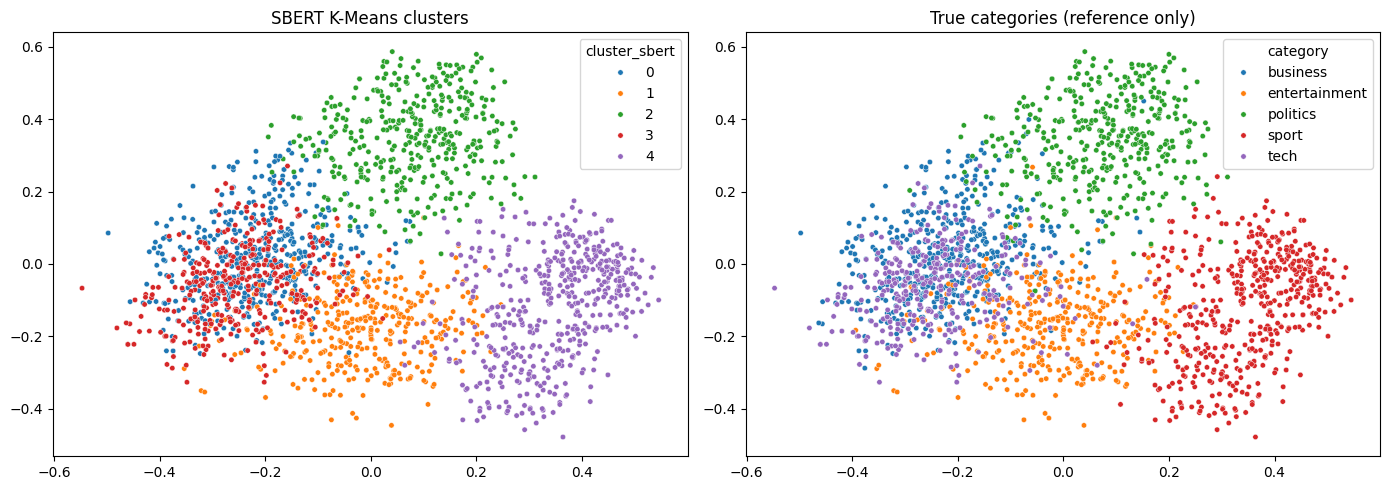

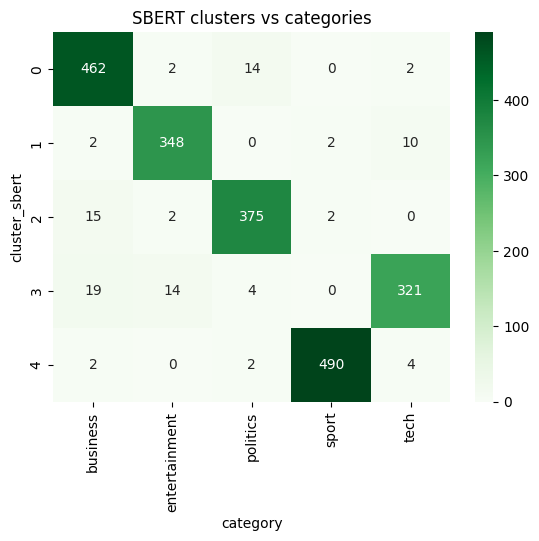

SBERT cluster 0 (n=480): company, firm, year, market, bank, sale, share, growth, price, economy
SBERT cluster 1 (n=362): film, award, best, star, show, year, band, music, actor, album
SBERT cluster 2 (n=394): labour, election, party, blair, government, would, tory, minister, brown, lord
SBERT cluster 3 (n=358): mobile, phone, people, technology, game, user, computer, service, software, network
SBERT cluster 4 (n=498): game, player, england, win, match, team, club, champion, cup, final


In [ ]:
km_sbert = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(emb)
df['cluster_sbert'] = km_sbert.labels_

emb2 = PCA(n_components=2, random_state=SEED).fit_transform(emb)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=emb2[:, 0], y=emb2[:, 1], hue=df['cluster_sbert'], palette='tab10', s=15, ax=ax[0]).set_title('SBERT K-Means clusters')
sns.scatterplot(x=emb2[:, 0], y=emb2[:, 1], hue=df['category'], palette='tab10', s=15, ax=ax[1]).set_title('True categories (reference only)')
plt.tight_layout(); plt.show()

ct2 = pd.crosstab(df['cluster_sbert'], df['category'])
sns.heatmap(ct2, annot=True, fmt='d', cmap='Greens'); plt.title('SBERT clusters vs categories'); plt.show()

# Describe SBERT clusters using TF-IDF keywords of the articles inside each cluster
for c in range(K):
    idx = df.index[df['cluster_sbert'] == c]
    w = np.asarray(X_tfidf[idx].mean(axis=0)).ravel()
    print(f'SBERT cluster {c} (n={len(idx)}):', ', '.join(terms[w.argsort()[::-1][:10]]))

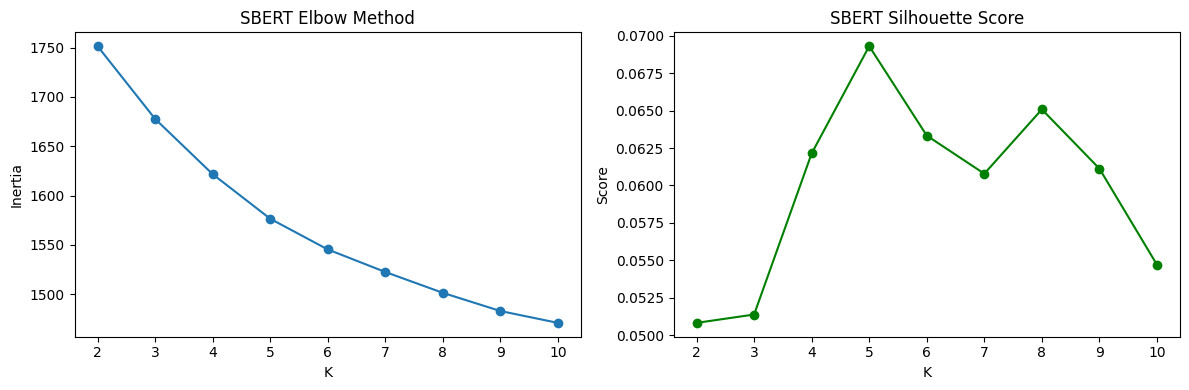

{2: np.float32(0.0508), 3: np.float32(0.0514), 4: np.float32(0.0621), 5: np.float32(0.0693), 6: np.float32(0.0633), 7: np.float32(0.0608), 8: np.float32(0.0651), 9: np.float32(0.0611), 10: np.float32(0.0547)}


In [ ]:
# Check K for the SBERT embeddings too (same Elbow + Silhouette as for TF-IDF)
sb_inertia, sb_sil = [], []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(emb)
    sb_inertia.append(km_k.inertia_)
    sb_sil.append(silhouette_score(emb, km_k.labels_, sample_size=2000, random_state=SEED))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_RANGE, sb_inertia, 'o-'); ax[0].set(title='SBERT Elbow Method', xlabel='K', ylabel='Inertia')
ax[1].plot(K_RANGE, sb_sil, 'o-', color='green'); ax[1].set(title='SBERT Silhouette Score', xlabel='K', ylabel='Score')
plt.tight_layout(); plt.show()
print(dict(zip(K_RANGE, np.round(sb_sil, 4))))

### Interpretation of the SBERT clusters (2.5)
| Cluster | Size | Interpretation | Main true category |
|---|---|---|---|
| 0 | 480 | **Business/economy** | business 462 |
| 1 | 362 | **Entertainment** (film, music, TV) | entertainment 348 |
| 2 | 394 | **Politics** | politics 375 |
| 3 | 358 | **Technology** | tech 321 |
| 4 | 498 | **Sport** | sport 490 |

SBERT produces five clusters that line up almost one-to-one with the true categories and with cluster sizes close to the real class sizes. In particular it **separates tech from entertainment**, the pair TF-IDF confused. Remaining errors are small and plausible: 19 tech-like articles (business/tech stories about companies) fall in the tech cluster from business, and 15 business articles land in politics (economic policy). Purity is **(462+348+375+321+490)/2092 = 95.4%**.

## 6. Result Analysis: measuring cluster quality
- **Silhouette Score** (internal, no labels): how well-separated clusters are, -1 to 1. Caveat: computed in different vector spaces, so compare with care.
- **Adjusted Rand Index (ARI)**, **Normalized Mutual Information (NMI)**, **Homogeneity**, **Completeness** (external, use true categories): how well clusters match the human categories. ARI/NMI of 1 = perfect match. These are the fairest basis for comparing TF-IDF vs SBERT.

In [ ]:
def evaluate(X, labels, name):
    y = df['category']
    return {'Method': name,
            'Silhouette': silhouette_score(X, labels, sample_size=2000, random_state=SEED),
            'ARI': adjusted_rand_score(y, labels),
            'NMI': normalized_mutual_info_score(y, labels),
            'Homogeneity': homogeneity_score(y, labels),
            'Completeness': completeness_score(y, labels)}
results = pd.DataFrame([evaluate(X_tfidf, df['cluster_tfidf'], 'TF-IDF + K-Means'),
                        evaluate(emb, df['cluster_sbert'], 'SBERT + K-Means')]).set_index('Method').round(4)
results

,Silhouette,ARI,NMI,Homogeneity,Completeness
Method,,,,,
TF-IDF + K-Means,0.0175,0.6939,0.7403,0.7240,0.7573
SBERT + K-Means,0.0693,0.8934,0.8641,0.8648,0.8633


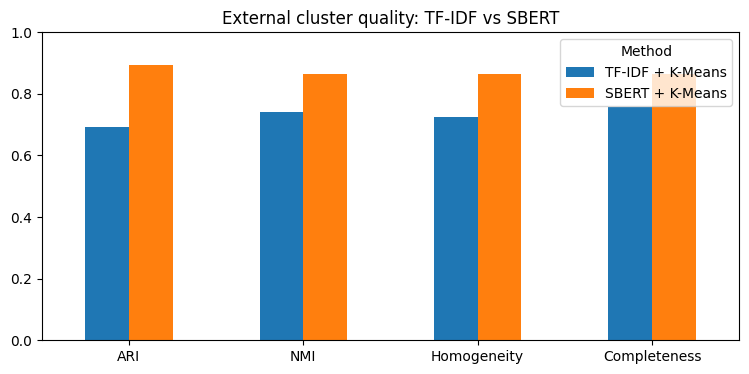

In [ ]:
results.drop(columns='Silhouette').T.plot.bar(figsize=(9, 4), rot=0, title='External cluster quality: TF-IDF vs SBERT')
plt.ylim(0, 1); plt.show()

In [ ]:
# Cluster purity = share of articles that sit in the majority true category of their cluster
def purity(labels):
    ct = pd.crosstab(labels, df['category'])
    return ct.max(axis=1).sum() / ct.values.sum()
print(f"TF-IDF purity: {purity(df['cluster_tfidf']):.3f}")
print(f"SBERT  purity: {purity(df['cluster_sbert']):.3f}")

TF-IDF purity: 0.834
SBERT  purity: 0.954


## 7. Conclusions and Recommendations (2.6)

### Effectiveness of the approaches
| Metric | TF-IDF + K-Means | SBERT + K-Means |
|---|---|---|
| Silhouette (internal) | 0.0175 | 0.0693 |
| Adjusted Rand Index | 0.694 | **0.893** |
| NMI | 0.740 | **0.864** |
| Homogeneity | 0.724 | **0.865** |
| Completeness | 0.757 | **0.863** |
| Purity | 83.4% | **95.4%** |

- **TF-IDF + K-Means** worked well for topics with distinctive vocabulary (sport, politics, business, film) and its clusters are easy to explain because we can read the key terms. However, it merged tech with a large part of entertainment, giving a mixed cluster of 620 articles, because the two share words and TF-IDF has no notion of meaning.
- **SBERT + K-Means** was clearly better on every external measure (ARI +0.20, NMI +0.12). It separated all five topics and had few mistakes, because the embeddings place semantically similar articles close together even when the exact words differ.
- **Measuring quality.** Silhouette (internal, no labels) was used to choose K and gives SBERT a higher value, but both values are low and are computed in different vector spaces (sparse 5,000-d vs dense 384-d), so it is not a fair head-to-head comparison. The external measures (ARI, NMI, homogeneity, completeness, purity) use the BBC categories as ground truth only for evaluation and are the fair basis for comparing the two methods.

### Trade-offs
| | TF-IDF | SBERT |
|---|---|---|
| Speed / resources | Very fast, no model download | Slower, needs a pre-trained model (~90 MB) |
| Interpretability | High: key terms are directly visible | Lower: dimensions have no meaning (we used TF-IDF terms to label clusters) |
| Semantics | Ignores meaning/synonyms | Captures meaning and context |
| Input handling | Uses the whole article | Truncates at ~256 tokens (reads the article opening) |

### Recommendation
For this dataset, **use Sentence-BERT embeddings with K-Means (K=5)**: it achieves ~95% purity and ARI 0.89 versus ~83% and 0.69 for TF-IDF, and its main cost (slower encoding of ~2,000 articles) is small. **TF-IDF should still be used to *describe* the clusters** by extracting the top terms from each SBERT cluster, as done in Section 5, which combines SBERT's accuracy with TF-IDF's interpretability. TF-IDF alone remains a sensible choice when compute is limited or full transparency is required.

### Limitations
- K-Means assumes roughly spherical clusters of similar size, and results depend on the random seed (we used `n_init=10` and a fixed seed).
- Silhouette scores are low in both spaces, so the choice of K relied partly on the known number of categories, which would not be available in a truly unlabelled setting.
- SBERT truncates long articles. The lemmatiser is not POS-aware (e.g. *media* -> *medium*). BBC articles are from 2004-2005, so vocabulary is dated.

### Future work
Try HDBSCAN or agglomerative clustering, topic models (LDA, BERTopic), larger embedding models (e.g. `all-mpnet-base-v2`), POS-aware lemmatisation, and a custom stop-word list.